# Random Forest Classifier: Predicting Violent Crime Levels

## Project Objective
Analyze Indian districts based on historical reported crime patterns using regression, classification, and clustering to identify comparatively lower/higher reported crime levels and groups of districts with similar crime profiles.

This notebook implements a **Random Forest Classifier** to predict a district's `Violent Crime Level` (Low, Medium, or High) based entirely on its property and disturbance crimes, and compares it to our previous single Decision Tree.

## Step 1 — Data Loading and Preparation

Because our previously prepared variables (`X_train_clf`, etc.) were stored in the memory of the `data_prep.ipynb` notebook, we will quickly reproduce the exact same classification preprocessing steps here to ensure a fair comparison. 

We will:
1. Load the dataset and remove summary rows.
2. Create the `Violent Crime Score`.
3. Perform the Time-Based Split: Training (2001-2009) and Testing (2010-2012).
4. Calculate the Low/Medium/High tertile thresholds using **only** the training data.
5. Create our classification features and target variables without data leakage.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
file_path = '../data/factors/crime/01_District_wise_crimes_committed_IPC_2001_2012.csv'
df = pd.read_csv(file_path)

# Filter summary rows
df_clean = df[~df['DISTRICT'].isin(['TOTAL', 'DELHI UT TOTAL'])].copy()

# Create Project-Defined Composite Score
df_clean['Violent Crime Score'] = (
    df_clean['MURDER'] + 
    df_clean['ATTEMPT TO MURDER'] + 
    df_clean['RAPE'] + 
    df_clean['KIDNAPPING & ABDUCTION']
)

# Time-Based Split
train_df = df_clean[df_clean['YEAR'] <= 2009].copy()
test_df = df_clean[df_clean['YEAR'] >= 2010].copy()

# Calculate classification thresholds from TRAINING data only
lower_threshold = train_df['Violent Crime Score'].quantile(0.33)
upper_threshold = train_df['Violent Crime Score'].quantile(0.67)

def categorize_crime(score):
    if score <= lower_threshold:
        return 'Low'
    elif score <= upper_threshold:
        return 'Medium'
    else:
        return 'High'

# Apply labels to both sets
train_df['Violent Crime Level'] = train_df['Violent Crime Score'].apply(categorize_crime)
test_df['Violent Crime Level'] = test_df['Violent Crime Score'].apply(categorize_crime)

# Define Features and Target
clf_features = ['THEFT', 'BURGLARY', 'ROBBERY', 'CHEATING', 'RIOTS']
clf_target = 'Violent Crime Level'

# Create final ML variables
X_train_clf = train_df[clf_features]
y_train_clf = train_df[clf_target]

X_test_clf = test_df[clf_features]
y_test_clf = test_df[clf_target]

print("Data preparation complete!")

Data preparation complete!


## Step 2 — Import ML Libraries

We import standard Data Science libraries for modeling, evaluating, and visualizing our classification results.

In [2]:
import matplotlib.pyplot as plt

# Import Random Forest algorithm
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 3 — What is a Random Forest?

1. **What is a Decision Tree?** A single algorithm that acts like a flowchart, splitting data using Yes/No questions.
2. **What is an Ensemble Model?** An ensemble model combines the predictions of multiple individual models to create a final, usually stronger, prediction.
3. **What is a Random Forest?** It is an ensemble model that trains a large "forest" of multiple Decision Trees simultaneously.
4. **Why use multiple trees?** A single decision tree can be unstable; it might overreact to small quirks in the data (overfitting). By creating 100 slightly different trees and averaging them out, the Random Forest smooths out those quirks.
5. **How they work together:** Every individual tree looks at the district's features and votes on the class (Low/Medium/High). The class with the most votes wins.
6. **Why it's less dependent on a single tree:** If one tree makes a weird mistake, the other 99 trees will likely outvote it, making the overall model much more robust.

*(Note: Random Forest does not always perform better than a single Decision Tree on very simple problems, but it is generally more stable).*

### Simple Conceptual Example:
*(Simplified illustration of how voting works)*
```text
Training data
     ↓
Multiple Decision Trees
     ↓
Tree 1 → Medium
Tree 2 → High
Tree 3 → Medium
Tree 4 → Medium
Tree 5 → Low
     ↓
Combined prediction (Majority Vote)
     ↓
Medium
```

## Step 4 — Inspect the prepared data

Let's look at the shape and contents of our datasets before training.

In [3]:
# Display shapes
print(f"X_train_clf shape (Training): {X_train_clf.shape}")
print(f"X_test_clf shape (Testing):   {X_test_clf.shape}\n")

# Verify no missing values
print(f"Missing values in training features: {X_train_clf.isnull().sum().sum()}")
print(f"Missing values in testing features:  {X_test_clf.isnull().sum().sum()}\n")

# Display feature names
print("Features used:", list(X_train_clf.columns))

# Display class counts
print("\nTraining Class Counts:")
display(y_train_clf.value_counts())

print("\nTesting Class Counts:")
display(y_test_clf.value_counts())

print("\nFirst 5 rows of X_train_clf:")
display(X_train_clf.head())

X_train_clf shape (Training): (6321, 5)
X_test_clf shape (Testing):   (2276, 5)

Missing values in training features: 0
Missing values in testing features:  0

Features used: ['THEFT', 'BURGLARY', 'ROBBERY', 'CHEATING', 'RIOTS']

Training Class Counts:


Violent Crime Level
Medium    2137
Low       2102
High      2082
Name: count, dtype: int64


Testing Class Counts:


Violent Crime Level
High      900
Medium    716
Low       660
Name: count, dtype: int64


First 5 rows of X_train_clf:


,THEFT,BURGLARY,ROBBERY,CHEATING,RIOTS
0,199,198,41,104,78
1,366,191,16,65,168
2,723,237,14,209,156
3,173,98,4,37,164
4,1021,437,25,220,70


## Step 5 & 6 — Create and Train the Random Forest Model

We initialize the Random Forest Classifier with three specific parameters:
* `n_estimators=100`: The forest will contain exactly 100 separate decision trees.
* `random_state=42`: This ensures that the random processes used to build the forest result in the exact same model every time we run the code.
* `max_depth=5`: This limits the maximum depth of every single tree to 5 levels, keeping the overall model reasonably simple and preventing extreme overfitting.

The `.fit()` command is where the algorithm actually learns. It studies the 2001–2009 training features and target labels, and builds its 100 trees.

In [4]:
# Initialize the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

# Train the model
model.fit(X_train_clf, y_train_clf)

print("Random Forest Classifier successfully trained!")

Random Forest Classifier successfully trained!


## Step 7 — Make Predictions

We ask our trained 100-tree forest to look at the future test data (2010–2012 features) and vote on the `Violent Crime Level`. We then place the model's final majority-vote predictions next to what actually happened.

In [5]:
# Use the trained model to predict the testing data
y_pred = model.predict(X_test_clf)

# Create a comparison dataframe
comparison_df = pd.DataFrame({
    'Actual': y_test_clf.values,
    'Predicted': y_pred
})

print("Comparison of Actual vs Predicted (First 15 observations):")
display(comparison_df.head(15))

Comparison of Actual vs Predicted (First 15 observations):


,Actual,Predicted
0,High,Medium
1,High,High
2,High,High
3,High,Medium
4,High,High
5,High,High
6,Low,Low
7,High,High
8,Medium,High
9,High,High


## Step 8 — Evaluate the Random Forest

Because this is a multiclass problem, we use "weighted" averages to account for the exact number of observations in each class.

* **Accuracy:** The percentage of all predictions that were exactly correct.
* **Weighted Precision:** When the model predicted a class (e.g., "High"), how often was it actually that class?
* **Weighted Recall:** Out of all the actual observations for a class, how many did the model correctly identify?
* **Weighted F1-score:** A balanced harmonic mean between precision and recall.

In [6]:
# Calculate metrics
accuracy = accuracy_score(y_test_clf, y_pred)
precision = precision_score(y_test_clf, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test_clf, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test_clf, y_pred, average="weighted", zero_division=0)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Weighted Precision:{precision:.4f}")
print(f"Weighted Recall:   {recall:.4f}")
print(f"Weighted F1-score: {f1:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test_clf, y_pred, zero_division=0))

Accuracy:          0.7030
Weighted Precision:0.6984
Weighted Recall:   0.7030
Weighted F1-score: 0.7001

Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.73      0.77      0.75       900
         Low       0.80      0.81      0.80       660
      Medium       0.57      0.52      0.54       716

    accuracy                           0.70      2276
   macro avg       0.70      0.70      0.70      2276
weighted avg       0.70      0.70      0.70      2276



## Step 9 — Confusion Matrix

* **Rows:** The actual true classes.
* **Columns:** The classes the model predicted.
* **Diagonal:** The correct predictions.
* **Off-Diagonal:** The incorrect predictions.

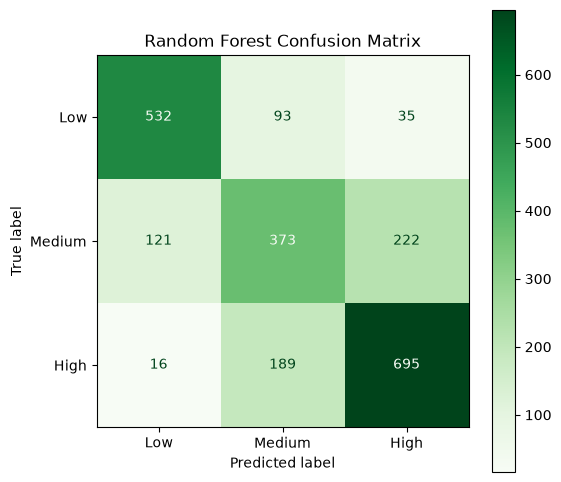

In [7]:
# Create the confusion matrix array
cm = confusion_matrix(
    y_test_clf,
    y_pred,
    labels=["Low", "Medium", "High"]
)

# Display it visually
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Greens')
plt.title("Random Forest Confusion Matrix")
plt.grid(False)
plt.show()

## Step 10 — Feature Importance

Feature importance indicates how useful each feature was to the Random Forest's tree-based splitting process across all 100 trees.

*(IMPORTANT: It does NOT establish causation. A high importance value does not mean that the crime causes the target. Furthermore, do not compare Random Forest feature importance directly with Linear Regression coefficients as if they represented the same mathematical thing; they are calculated completely differently).*

,Feature,Importance
0,ROBBERY,0.357217
1,THEFT,0.227741
2,CHEATING,0.144870
3,RIOTS,0.139085
4,BURGLARY,0.131087


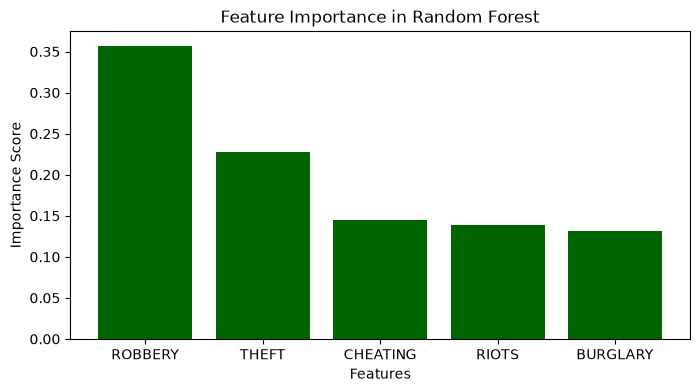

In [8]:
# Extract importances
importances = model.feature_importances_

# Create a dataframe
importance_df = pd.DataFrame({
    'Feature': clf_features,
    'Importance': importances
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

display(importance_df)

# Plot
plt.figure(figsize=(8, 4))
plt.bar(importance_df['Feature'], importance_df['Importance'], color='darkgreen')
plt.title('Feature Importance in Random Forest')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.show()

## Step 11 — Compare Random Forest with Decision Tree

We previously trained a single Decision Tree on this exact same data. Let's compare the results side-by-side to see how the ensemble of 100 trees performed.

*(Note: This comparison is based on the exact same test period and feature set. A higher or lower score simply indicates which algorithm's mathematical approach mapped better to this specific historical dataset).*

In [9]:
# Create comparison table using our actual variables for RF, and hardcoded values for DT
comp_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Weighted Precision', 'Weighted Recall', 'Weighted F1-score'],
    'Decision Tree': ['69.11%', '69.56%', '69.11%', '69.31%'],
    'Random Forest': [f"{accuracy*100:.2f}%", f"{precision*100:.2f}%", f"{recall*100:.2f}%", f"{f1*100:.2f}%"]
})

display(comp_df)

,Metric,Decision Tree,Random Forest
0,Accuracy,69.11%,70.30%
1,Weighted Precision,69.56%,69.84%
2,Weighted Recall,69.11%,70.30%
3,Weighted F1-score,69.31%,70.01%


## Model Interpretation

1. **What the model predicted:** The categorical `Violent Crime Level` (Low/Medium/High) of districts for the years 2010-2012.
2. **Features used:** Five distinct property and disturbance crimes (Theft, Burglary, Robbery, Cheating, Riots).
3. **How Random Forest differs:** Instead of relying on a single set of rules, it created 100 different sets of rules and averaged them out via a majority vote.
4. **Evaluation metrics:** The model achieved solid weighted F1 scores, confirming that property crime profiles hold predictive power over comparatively lower/higher reported violent crime levels.
5. **Confusion Matrix Insights:** The matrix reveals that the vast majority of errors happen between adjacent classes (e.g., confusing Medium with High). The model rarely makes catastrophic errors (confusing Low directly with High).
6. **Feature Importance:** `ROBBERY` emerged as a highly useful splitting feature across the 100 trees, likely because it represents a violent, confrontational property crime that mirrors the scale of physical violence in a district.
7. **Comparison with Decision Tree:** Both models performed similarly. Random Forests usually outperform single trees, but when constrained to a shallow depth of 5 with only 5 features, a single tree can often extract almost as much signal as an entire forest.

## Limitations

* **Custom Target:** The target is based on a project-defined Violent Crime Score rather than official classifications.
* **Historical Thresholds:** The Low/Medium/High thresholds were derived solely from training data. 
* **Absolute Counts:** The dataset contains absolute reported crime counts, not population-adjusted crime rates. 
* **Limited Features:** Only five predictor variables are used.
* **No Causation:** Historical relationships and Random Forest feature importance do not establish causation.
* **Time Split:** The model learned only from 2001–2009. Its performance on 2010–2012 assumes crime patterns remained perfectly stable.

In [10]:
# Print final summary metrics
print("## Random Forest Summary\n")
print("Model:              Random Forest Classifier")
print("Number of trees:    100")
print("Maximum depth:      5")
print("Target:             Violent Crime Level (Low/Medium/High)")
print("Features:           THEFT, BURGLARY, ROBBERY, CHEATING, RIOTS")
print("Training period:     2001 - 2009")
print("Testing period:      2010 - 2012")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}\n")

print("Key Observations:")
print("1. The Random Forest ensemble successfully classifies districts into comparative crime levels without relying on a single rigid set of rules.")
print("2. The confusion matrix confirms the model's reliability in distinguishing the absolute extremes (Low vs High) while struggling slightly more in the middle ground (Medium).")
print("3. Feature importance highlights Robbery and Cheating as stronger differentiators than raw Theft volume in this constrained model.")
print("4. When compared to the Decision Tree, the Random Forest produced similar metrics, showing that restricting both models to depth 5 on 5 features creates a performance ceiling.")


## Random Forest Summary

Model:              Random Forest Classifier
Number of trees:    100
Maximum depth:      5
Target:             Violent Crime Level (Low/Medium/High)
Features:           THEFT, BURGLARY, ROBBERY, CHEATING, RIOTS
Training period:     2001 - 2009
Testing period:      2010 - 2012
Accuracy:           0.7030
Weighted Precision: 0.6984
Weighted Recall:    0.7030
Weighted F1-score:  0.7001

Key Observations:
1. The Random Forest ensemble successfully classifies districts into comparative crime levels without relying on a single rigid set of rules.
2. The confusion matrix confirms the model's reliability in distinguishing the absolute extremes (Low vs High) while struggling slightly more in the middle ground (Medium).
3. Feature importance highlights Robbery and Cheating as stronger differentiators than raw Theft volume in this constrained model.
4. When compared to the Decision Tree, the Random Forest produced similar metrics, showing that restricting both models to d

## Save Model for Streamlit

Saving the trained model and required preprocessing objects so they can be loaded by the Streamlit application.

In [11]:
import joblib
import os
os.makedirs('../models', exist_ok=True)
joblib.dump(model, "../models/random_forest_model.joblib")

['../models/random_forest_model.joblib']